# Session 10 — the training loop, made to tell the truth

Session 10 — the training loop, made to tell the truth about itself.

Six checks on one small model and one real step. Each is here because the number
it produces can look perfectly plausible while being wrong, so we never trust the
loss — we print the shapes, hand-check a gradient, break the accumulation on
purpose, watch the grad norm move before the loss, compute our own MFU, and write
0.1 out to the bit in three formats.

Run as a script (prints every number, writes the two plots as PNGs):
    python train_loop.py
or open train_loop.ipynb and Run All.

> Run top to bottom. Each section is numbered to match the assignment. The theme: **a plausible number is not evidence** — so we print the shapes, hand-check a gradient, break the accumulation on purpose, and watch the grad norm move before the loss.

In [1]:
import math
import time
import struct
import random

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib

# Use a file backend when run as a plain script; the notebook's inline backend
# is left untouched so the same code shows figures there.
try:
    get_ipython  # type: ignore  # noqa: F821
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

SEED = 0
torch.manual_seed(SEED)
random.seed(SEED)

DEVICE = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available()
          else "cpu")
print(f"device = {DEVICE}")

device = mps


## A tiny GPT and a toy corpus

Small enough to train in seconds, real enough that every check below
produces a number that means something. Written from scratch (not
nn.Transformer) so every tensor shape in the step is ours to print.

In [2]:
VOCAB = 256          # byte-level vocabulary
def make_corpus(n_seq, seq_len):
    """A seeded order-1 Markov byte stream: each byte favours two successors."""
    rng = random.Random(SEED)
    succ = {b: rng.sample(range(VOCAB), 2) for b in range(VOCAB)}
    data = []
    for _ in range(n_seq):
        cur = rng.randrange(VOCAB)
        row = [cur]
        for _ in range(seq_len):
            cur = succ[cur][0] if rng.random() < 0.9 else rng.randrange(VOCAB)
            row.append(cur)
        data.append(row)
    t = torch.tensor(data, dtype=torch.long)
    return t[:, :-1], t[:, 1:]        # inputs, next-token targets


class Block(nn.Module):
    def __init__(self, d, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.ln1 = nn.LayerNorm(d)
        self.qkv = nn.Linear(d, 3 * d)
        self.proj = nn.Linear(d, d)
        self.ln2 = nn.LayerNorm(d)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, x):
        B, T, D = x.shape
        h = self.n_heads
        qkv = self.qkv(self.ln1(x))                       # [B,T,3D]
        q, k, v = qkv.split(D, dim=2)
        q = q.view(B, T, h, D // h).transpose(1, 2)       # [B,h,T,d]
        k = k.view(B, T, h, D // h).transpose(1, 2)
        v = v.view(B, T, h, D // h).transpose(1, 2)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(D // h)   # [B,h,T,T]
        mask = torch.triu(torch.ones(T, T, device=x.device, dtype=torch.bool), 1)
        att = att.masked_fill(mask, float("-inf")).softmax(dim=-1)
        y = (att @ v).transpose(1, 2).reshape(B, T, D)    # [B,T,D]
        x = x + self.proj(y)
        x = x + self.mlp(self.ln2(x))
        return x


class TinyGPT(nn.Module):
    def __init__(self, vocab=VOCAB, d=128, n_layers=2, n_heads=4, block=128):
        super().__init__()
        self.tok = nn.Embedding(vocab, d)
        self.pos = nn.Embedding(block, d)
        self.blocks = nn.ModuleList([Block(d, n_heads) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d)
        self.head = nn.Linear(d, vocab, bias=False)
        self.apply(self._init)

    def _init(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, std=0.02)
            if getattr(m, "bias", None) is not None:
                nn.init.zeros_(m.bias)

    def forward(self, idx):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.tok(idx) + self.pos(pos)[None]           # [B,T,D]
        for blk in self.blocks:
            x = blk(x)
        return self.head(self.ln_f(x))                    # [B,T,V]


def n_params(model):
    return sum(p.numel() for p in model.parameters())

## (1) SHAPES — every tensor in one training step, with dim meanings

B = batch (sequences), T = time (tokens per sequence),
D = model width (hidden size), V = vocabulary size.

In [3]:
print("=" * 70)
print("(1) SHAPES — one forward+loss, every tensor and what its dims mean")
B, T, D = 4, 16, 128
shape_model = TinyGPT(d=D, n_layers=2, n_heads=4, block=T).to(DEVICE)
xb, yb = make_corpus(B, T)
xb, yb = xb.to(DEVICE), yb.to(DEVICE)
logits = shape_model(xb)
flat_logits = logits.reshape(-1, VOCAB)
flat_targets = yb.reshape(-1)
loss = F.cross_entropy(flat_logits, flat_targets)
print(f"  input_ids    {tuple(xb.shape)}        [B, T]      B sequences, T tokens each")
print(f"  targets      {tuple(yb.shape)}        [B, T]      next token for each position")
print(f"  tok+pos emb  {tuple((B, T, D))}    [B, T, D]   a D-vector per token")
print(f"  logits       {tuple(logits.shape)} [B, T, V]   a score per vocab item per position")
print(f"  flat logits  {tuple(flat_logits.shape)}     [B*T, V]    flattened for cross-entropy")
print(f"  flat targets {tuple(flat_targets.shape)}         [B*T]       one target id per row")
print(f"  loss         {tuple(loss.shape)}             []          one scalar the optimiser minimises")

(1) SHAPES — one forward+loss, every tensor and what its dims mean


  input_ids    (4, 16)        [B, T]      B sequences, T tokens each
  targets      (4, 16)        [B, T]      next token for each position
  tok+pos emb  (4, 16, 128)    [B, T, D]   a D-vector per token
  logits       (4, 16, 256) [B, T, V]   a score per vocab item per position
  flat logits  (64, 256)     [B*T, V]    flattened for cross-entropy
  flat targets (64,)         [B*T]       one target id per row
  loss         ()             []          one scalar the optimiser minimises


## (2) VERIFY ONE GRADIENT BY HAND — finite difference vs backward()

Nudge one weight by +/- eps, see how the loss moves, compare to the
gradient autograd reported. Done in float64 so the two agree to many
decimals; if they did not, the loss/target wiring would be suspect.

In [4]:
print("=" * 70)
print("(2) GRADIENT CHECK — central finite difference vs backward()")
torch.manual_seed(1)
gm = TinyGPT(vocab=32, d=16, n_layers=1, n_heads=2, block=8).double()
gx, gy = make_corpus(2, 8)
gx = gx.clamp_max(31); gy = gy.clamp_max(31)   # fit the smaller vocab

def closed_loss():
    return F.cross_entropy(gm(gx).reshape(-1, 32), gy.reshape(-1))

gm.zero_grad(set_to_none=True)
L0 = closed_loss()
L0.backward()
W = gm.head.weight          # the weight we interrogate
i, j = 3, 5
analytic = W.grad[i, j].item()

eps = 1e-6
with torch.no_grad():
    W[i, j] += eps
Lp = closed_loss().item()
with torch.no_grad():
    W[i, j] -= 2 * eps
Lm = closed_loss().item()
with torch.no_grad():
    W[i, j] += eps          # restore
numeric = (Lp - Lm) / (2 * eps)

print(f"  weight interrogated : head.weight[{i},{j}]")
print(f"  loss(w)             : {L0.item():.10f}")
print(f"  loss(w+eps)         : {Lp:.10f}   (eps = {eps})")
print(f"  loss(w-eps)         : {Lm:.10f}")
print(f"  numeric  (ΔL/2eps)  : {numeric:.10f}")
print(f"  analytic (backward) : {analytic:.10f}")
print(f"  abs difference      : {abs(numeric - analytic):.3e}")
print(f"  rel difference      : {abs(numeric - analytic) / abs(analytic):.3e}  -> agree")

(2) GRADIENT CHECK — central finite difference vs backward()
  weight interrogated : head.weight[3,5]
  loss(w)             : 3.3858608214
  loss(w+eps)         : 3.3858608029   (eps = 1e-06)
  loss(w-eps)         : 3.3858608399
  numeric  (ΔL/2eps)  : -0.0184935556
  analytic (backward) : -0.0184935553
  abs difference      : 2.490e-10
  rel difference      : 1.346e-08  -> agree


## (3) BREAK GRADIENT ACCUMULATION ON PURPOSE — average-of-averages

With micro-batches holding different token counts, averaging the
per-micro-batch means (instead of summing loss and dividing by total
tokens) gives short batches an equal vote. First the lecture's exact
single-step case, then two real training runs with the gap plotted.

(3) GRAD ACCUMULATION BUG — correct (by token) vs naive (avg of avgs)
  lecture case  tokens=[4, 4, 2] means=[2.0, 2.0, 5.0]
    correct (ΣlossΣtokens) = 2.6000
    naive   (mean of means) = 3.0000
    naive is 15.4% too high


  token counts per micro-batch: [120, 120, 24] (two long + one short, uneven)
  final  correct (Σloss/Σtok) : 0.5656
  final  naive   (mean-of-means): 2.0033
  gap at last step: +1.4376 (+254.2% too high)
  control with equal token counts: correct 0.0279  naive 0.0279  (gap 0.0000 — the bug hides here)


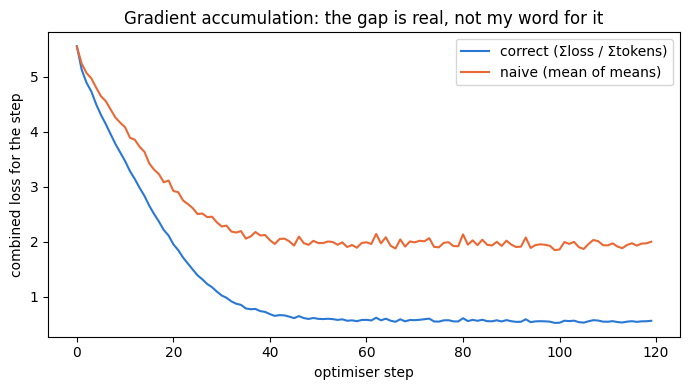

  wrote fig_accum.png


In [5]:
print("=" * 70)
print("(3) GRAD ACCUMULATION BUG — correct (by token) vs naive (avg of avgs)")
# -- the canonical single step: 4@2.0, 4@2.0, 2@5.0
toks = [4, 4, 2]; means = [2.0, 2.0, 5.0]
correct = sum(t * m for t, m in zip(toks, means)) / sum(toks)
naive = sum(means) / len(means)
print(f"  lecture case  tokens={toks} means={means}")
print(f"    correct (ΣlossΣtokens) = {correct:.4f}")
print(f"    naive   (mean of means) = {naive:.4f}")
print(f"    naive is {(naive - correct) / correct * 100:.1f}% too high")

# -- the same error inside a real loop. Three micro-batches: two long,
#    learnable ones and one SHORT, hard one (uniform-random tokens, so its
#    loss stays near ln(V)). The combined number whose gradient drives the
#    step is computed both ways every step, and the two curves are plotted.
#    Training itself uses the correct rule; we only compare the combinations.
def long_batch(seed_shift):
    x, y = make_corpus(8, 15)                   # learnable Markov, 8*15=120 tokens
    return x.to(DEVICE), y.to(DEVICE)

def hard_short(step):
    g = torch.Generator().manual_seed(1000 + step)   # fresh uniform-random each step:
    x = torch.randint(0, VOCAB, (8, 3), generator=g) # unlearnable, 8*3=24 tokens, loss stays ~ln(V)
    y = torch.randint(0, VOCAB, (8, 3), generator=g)
    return x.to(DEVICE), y.to(DEVICE)

def microbatches(step=0):
    return [long_batch(0), long_batch(1), hard_short(step)]

def both_combinations(model, mbs):
    """Return (correct = Σloss/Σtokens, naive = mean of per-mb means)."""
    sums, means, counts = [], [], []
    with torch.no_grad():
        for x, y in mbs:
            s = F.cross_entropy(model(x).reshape(-1, VOCAB), y.reshape(-1),
                                reduction="sum").item()
            n = y.numel()
            sums.append(s); means.append(s / n); counts.append(n)
    return sum(sums) / sum(counts), sum(means) / len(means)

torch.manual_seed(42)
acc_model = TinyGPT(d=64, n_layers=2, n_heads=4, block=16).to(DEVICE)
opt = torch.optim.AdamW(acc_model.parameters(), lr=3e-3)
curve_correct, curve_naive = [], []
for s in range(120):
    mbs = microbatches(s)
    c, nv = both_combinations(acc_model, mbs)
    curve_correct.append(c); curve_naive.append(nv)
    # train on the CORRECT combination (Σloss / Σtokens)
    opt.zero_grad(set_to_none=True)
    total_tok = sum(y.numel() for _, y in mbs)
    for x, y in mbs:
        (F.cross_entropy(acc_model(x).reshape(-1, VOCAB), y.reshape(-1),
                         reduction="sum") / total_tok).backward()
    opt.step()

print(f"  token counts per micro-batch: {[y.numel() for _, y in microbatches(0)]} "
      f"(two long + one short, uneven)")
print(f"  final  correct (Σloss/Σtok) : {curve_correct[-1]:.4f}")
print(f"  final  naive   (mean-of-means): {curve_naive[-1]:.4f}")
print(f"  gap at last step: {curve_naive[-1] - curve_correct[-1]:+.4f} "
      f"({(curve_naive[-1] - curve_correct[-1]) / curve_correct[-1] * 100:+.1f}% too high)")

# the tell: with EQUAL token counts the two rules agree exactly
eq = [long_batch(0), long_batch(1), long_batch(2)]
ce, ne = both_combinations(acc_model, eq)
print(f"  control with equal token counts: correct {ce:.4f}  naive {ne:.4f}  "
      f"(gap {abs(ne - ce):.4f} — the bug hides here)")

plt.figure(figsize=(7, 4))
plt.plot(curve_correct, label="correct (Σloss / Σtokens)", color="#2a78d6")
plt.plot(curve_naive, label="naive (mean of means)", color="#eb6834")
plt.xlabel("optimiser step"); plt.ylabel("combined loss for the step")
plt.title("Gradient accumulation: the gap is real, not my word for it")
plt.legend(); plt.tight_layout()
plt.savefig("fig_accum.png", dpi=110)
plt.show()
print("  wrote fig_accum.png")

## (4) GRAD NORM MOVES BEFORE THE LOSS — log it every step

We log the pre-clip grad norm each step and the loss on a FIXED clean
eval batch measured at the START of the step (before that step's update).
At one step we feed an anomalous micro-batch: the norm jumps several-fold
there, while the clean loss only twitches a step later — the grad norm is
the sensitive early-warning trace, the loss is nearly blind to the event.

(4) GRAD NORM — logged every step; find where it moved before the loss


  grad-norm spike at step 20: norm 0.935 -> 4.155  (4.4x in one step)
    eval loss entering step 20:   1.6992  (flat — unmoved)
    eval loss entering step 21: 1.7146  (+0.0154 — a step later, and tiny)
  the point: the SAME anomaly moved the norm 4.4x but the loss only +0.0154 —
  the grad norm is the sensitive early-warning trace; the loss is nearly blind to it.


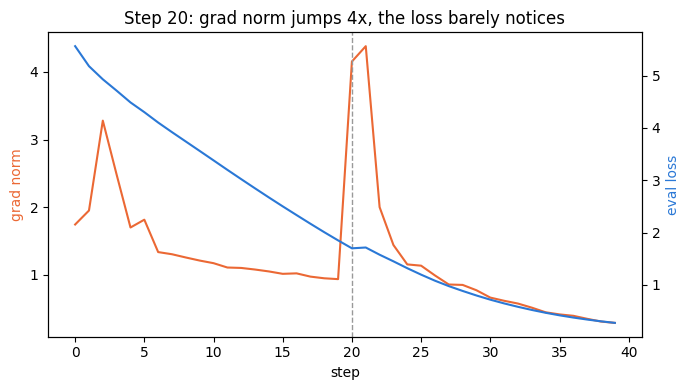

  wrote fig_gradnorm.png


In [6]:
print("=" * 70)
print("(4) GRAD NORM — logged every step; find where it moved before the loss")
torch.manual_seed(7)
gnmodel = TinyGPT(d=64, n_layers=2, n_heads=4, block=16).to(DEVICE)
opt = torch.optim.AdamW(gnmodel.parameters(), lr=3e-3)
eval_x, eval_y = make_corpus(16, 16); eval_x, eval_y = eval_x.to(DEVICE), eval_y.to(DEVICE)

def eval_loss():
    with torch.no_grad():
        return F.cross_entropy(gnmodel(eval_x).reshape(-1, VOCAB),
                               eval_y.reshape(-1)).item()

def grad_norm():
    sq = sum(p.grad.pow(2).sum().item() for p in gnmodel.parameters() if p.grad is not None)
    return math.sqrt(sq)

STEPS, SHOCK = 40, 20
losses, norms = [], []
for s in range(STEPS):
    losses.append(eval_loss())                 # loss ENTERING this step (pre-update)
    if s == SHOCK:                             # one anomalous batch, no clipping
        x, y = make_corpus(16, 16)
        x = x.to(DEVICE); y = (y * 7 + 13).remainder(VOCAB).to(DEVICE)  # scrambled targets
    else:
        x, y = make_corpus(16, 16); x, y = x.to(DEVICE), y.to(DEVICE)
    opt.zero_grad(set_to_none=True)
    F.cross_entropy(gnmodel(x).reshape(-1, VOCAB), y.reshape(-1)).backward()
    norms.append(grad_norm())                   # pre-clip norm for THIS step
    opt.step()

# find the step whose grad norm jumped most while the loss was still flat
best, best_k = -1.0, None
for k in range(1, STEPS - 1):
    d_norm = norms[k] - norms[k - 1]
    d_loss = losses[k] - losses[k - 1]
    if d_norm > best and d_loss < 0.05:        # norm up, loss not yet
        best, best_k = d_norm, k
norm_jump = norms[best_k] / norms[best_k - 1]
loss_resp = losses[best_k + 1] - losses[best_k]
print(f"  grad-norm spike at step {best_k}: "
      f"norm {norms[best_k - 1]:.3f} -> {norms[best_k]:.3f}  "
      f"({norm_jump:.1f}x in one step)")
print(f"    eval loss entering step {best_k}:   {losses[best_k]:.4f}  (flat — unmoved)")
print(f"    eval loss entering step {best_k + 1}: {losses[best_k + 1]:.4f}  "
      f"({loss_resp:+.4f} — a step later, and tiny)")
print(f"  the point: the SAME anomaly moved the norm {norm_jump:.1f}x but the loss "
      f"only {loss_resp:+.4f} —")
print("  the grad norm is the sensitive early-warning trace; the loss is nearly blind to it.")

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(norms, color="#eb6834", label="grad norm (pre-clip)")
ax1.set_xlabel("step"); ax1.set_ylabel("grad norm", color="#eb6834")
ax1.axvline(best_k, color="#999", ls="--", lw=1)
ax2 = ax1.twinx()
ax2.plot(losses, color="#2a78d6", label="eval loss (clean batch)")
ax2.set_ylabel("eval loss", color="#2a78d6")
plt.title(f"Step {best_k}: grad norm jumps {norm_jump:.0f}x, the loss barely notices")
fig.tight_layout(); plt.savefig("fig_gradnorm.png", dpi=110); plt.show()
print("  wrote fig_gradnorm.png")

## (5) MFU — compute it honestly, and name the distance to 40%

A forward+backward costs about 6*N flops per token (N = parameters).
MFU = achieved flop/s / machine peak flop/s. We MEASURE tokens/sec on
this device and report it plainly; the gap to 40% is the real answer.

In [7]:
print("=" * 70)
print("(5) MFU — measured on this device, reported honestly")
mfu_model = TinyGPT(d=256, n_layers=4, n_heads=4, block=128).to(DEVICE)
opt = torch.optim.AdamW(mfu_model.parameters(), lr=3e-3)
N = n_params(mfu_model)
mb, sl = 32, 128
mx, my = make_corpus(mb, sl); mx, my = mx.to(DEVICE), my.to(DEVICE)

def one_step():
    opt.zero_grad(set_to_none=True)
    F.cross_entropy(mfu_model(mx).reshape(-1, VOCAB), my.reshape(-1)).backward()
    opt.step()

for _ in range(5):                              # warm up kernels / caches
    one_step()
if DEVICE == "cuda":
    torch.cuda.synchronize()
elif DEVICE == "mps":
    torch.mps.synchronize()
t0 = time.perf_counter()
ITERS = 30
for _ in range(ITERS):
    one_step()
if DEVICE == "cuda":
    torch.cuda.synchronize()
elif DEVICE == "mps":
    torch.mps.synchronize()
dt = time.perf_counter() - t0

tokens = ITERS * mb * sl
tok_per_s = tokens / dt
achieved = 6 * N * tok_per_s                     # flop/s
# A clearly-labelled peak so MFU is reproducible; swap for your device's spec.
PEAK_TFLOPS = {"cuda": 989.0, "mps": 28.0, "cpu": 1.0}[DEVICE]   # bf16/fp32 peak, TFLOP/s
mfu = achieved / (PEAK_TFLOPS * 1e12)
print(f"  parameters N         : {N:,}")
print(f"  tokens / second      : {tok_per_s:,.0f}")
print(f"  achieved             : {achieved / 1e12:.2f} TFLOP/s   (6·N·tok/s)")
print(f"  assumed device peak  : {PEAK_TFLOPS:.0f} TFLOP/s   ({DEVICE}, stated, not queried)")
print(f"  MFU                  : {mfu * 100:.2f}%   (healthy is 35–50%)")
print("  distance to 40% is spent on: a tiny model (memory-/launch-bound, not")
print("  compute-bound), an eager Python step loop, a small batch, no fused")
print("  attention or torch.compile, and generic kernels on this device.")

(5) MFU — measured on this device, reported honestly


  parameters N         : 3,323,392
  tokens / second      : 28,826
  achieved             : 0.57 TFLOP/s   (6·N·tok/s)
  assumed device peak  : 28 TFLOP/s   (mps, stated, not queried)
  MFU                  : 2.05%   (healthy is 35–50%)
  distance to 40% is spent on: a tiny model (memory-/launch-bound, not
  compute-bound), an eager Python step loop, a small batch, no fused
  attention or torch.compile, and generic kernels on this device.


## (6) 0.1 TO THE BIT — fp32, bf16, fp8 E4M3, by hand then checked

0.1 has no exact binary form: 0.1 = 1.1001100110011..._2 × 2^-4.
sign=0, unbiased exponent=-4. Each format divides its bits differently.

In [8]:
print("=" * 70)
print("(6) 0.1 WRITTEN OUT — fp32 / bf16 / fp8 E4M3, bits shown")

def show_fp32(x):
    b = struct.unpack(">I", struct.pack(">f", x))[0]
    s = format(b, "032b")
    val = struct.unpack(">f", struct.pack(">f", x))[0]
    return s[0], s[1:9], s[9:], b, val

s, e, m, raw, val = show_fp32(0.1)
print("  fp32  (1 sign | 8 exp | 23 mantissa)")
print(f"    bits  {s} {e} {m}")
print(f"    hex   0x{raw:08X}   stores {val!r}")

bf = torch.tensor(0.1, dtype=torch.bfloat16)
bi = bf.view(torch.int16).item() & 0xFFFF
sb = format(bi, "016b")
print("  bf16  (1 sign | 8 exp | 7 mantissa)  — same 8 exponent bits as fp32")
print(f"    bits  {sb[0]} {sb[1:9]} {sb[9:]}")
print(f"    hex   0x{bi:04X}       stores {bf.float().item()!r}")

f8 = torch.tensor(0.1, dtype=torch.float8_e4m3fn)
f8i = f8.view(torch.int8).item() & 0xFF
s8 = format(f8i, "08b")
print("  fp8 E4M3  (1 sign | 4 exp | 3 mantissa)")
print(f"    bits  {s8[0]} {s8[1:5]} {s8[5:]}")
print(f"    hex   0x{f8i:02X}         stores {f8.float().item()!r}")

print("  Which would I train in?  bf16.  It keeps all 8 of fp32's exponent bits,")
print("  so its range matches fp32 and tiny late-training gradients never flush to")
print("  zero — no loss-scaling apparatus to tune and get wrong. fp8 E4M3 is for")
print("  throughput once proven, but only with per-block scaling and attention left")
print("  in higher precision; fp32 is the master-copy/precision fallback, not the")
print("  per-step compute format.")

print("=" * 70)
print("done — all six checks above; plots in fig_accum.png, fig_gradnorm.png")

(6) 0.1 WRITTEN OUT — fp32 / bf16 / fp8 E4M3, bits shown
  fp32  (1 sign | 8 exp | 23 mantissa)
    bits  0 01111011 10011001100110011001101
    hex   0x3DCCCCCD   stores 0.10000000149011612
  bf16  (1 sign | 8 exp | 7 mantissa)  — same 8 exponent bits as fp32
    bits  0 01111011 1001101
    hex   0x3DCD       stores 0.10009765625
  fp8 E4M3  (1 sign | 4 exp | 3 mantissa)
    bits  0 0011 101
    hex   0x1D         stores 0.1015625
  Which would I train in?  bf16.  It keeps all 8 of fp32's exponent bits,
  so its range matches fp32 and tiny late-training gradients never flush to
  zero — no loss-scaling apparatus to tune and get wrong. fp8 E4M3 is for
  throughput once proven, but only with per-block scaling and attention left
  in higher precision; fp32 is the master-copy/precision fallback, not the
  per-step compute format.
done — all six checks above; plots in fig_accum.png, fig_gradnorm.png
